In [26]:
from math import erfc
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from matplotlib.ticker import PercentFormatter

In [27]:
futures = pl.read_parquet(
    "./../data/ttf futures/settlement/ttf_futures.parquet"
)

In [28]:
futures

TrdDate,Cmdty,Area,ShortCode,Maturity,InstrumentISIN,ProductType,ExpiryDate,Currency,UOM,Px,Tm,UpdtAct,CreationTm
str,str,str,str,str,str,str,str,str,str,f64,str,str,str
"""2022-01-03""","""NATGAS""","""TTF""","""G301""","""202201""","""DE000C3NBGS0""","""Future""","""2022-01-03""","""EUR""","""MWh""",70.258,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
"""2022-01-03""","""NATGAS""","""TTF""","""G302""","""202201""","""DE000C3NCKZ5""","""Future""","""2022-01-03""","""EUR""","""MWh""",70.258,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
"""2022-01-03""","""NATGAS""","""TTF""","""G303""","""202201""","""DE000C3NDJC4""","""Future""","""2022-01-03""","""EUR""","""MWh""",70.258,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
"""2022-01-03""","""NATGAS""","""TTF""","""G304""","""202201""","""DE000C3NDT89""","""Future""","""2022-01-04""","""EUR""","""MWh""",71.472,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
"""2022-01-03""","""NATGAS""","""TTF""","""G305""","""202201""","""DE000C3NECK0""","""Future""","""2022-01-05""","""EUR""","""MWh""",151.857,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""2026-09-28""","""NATGAS""","""TTF""","""LTTF""","""203205""","""DE000C3C0445""","""Future""","""2032-04-29""","""USD""","""MMBtu""",8.616,"""2026-09-28T16:13:00Z""","""NEW""","""2026-09-28T20:00:09Z"""
"""2026-09-28""","""NATGAS""","""TTF""","""LTTF""","""203206""","""DE000C3C3DT3""","""Future""","""2032-05-28""","""USD""","""MMBtu""",8.598,"""2026-09-28T16:13:00Z""","""NEW""","""2026-09-28T20:00:09Z"""
"""2026-09-28""","""NATGAS""","""TTF""","""LTTF""","""203207""","""DE000C3C6XE6""","""Future""","""2032-06-29""","""USD""","""MMBtu""",8.632,"""2026-09-28T16:13:00Z""","""NEW""","""2026-09-28T20:00:09Z"""


In [ ]:
monthly_futures = futures.filter(pl.col("ShortCode") == "G3BM").sort("TrdDate")
monthly_futures

TrdDate,Cmdty,Area,ShortCode,Maturity,InstrumentISIN,ProductType,ExpiryDate,Currency,UOM,Px,Tm,UpdtAct,CreationTm
str,str,str,str,str,str,str,str,str,str,f64,str,str,str
"""2022-01-03""","""NATGAS""","""TTF""","""G3BM""","""202202""","""DE000C273EV9""","""Future""","""2022-02-24""","""EUR""","""MWh""",80.17,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
"""2022-01-03""","""NATGAS""","""TTF""","""G3BM""","""202203""","""DE000C2740Y2""","""Future""","""2022-03-29""","""EUR""","""MWh""",78.6,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
"""2022-01-03""","""NATGAS""","""TTF""","""G3BM""","""202204""","""DE000C2746P7""","""Future""","""2022-04-28""","""EUR""","""MWh""",73.41,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
"""2022-01-03""","""NATGAS""","""TTF""","""G3BM""","""202205""","""DE000C274HA4""","""Future""","""2022-05-27""","""EUR""","""MWh""",72.06,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
"""2022-01-03""","""NATGAS""","""TTF""","""G3BM""","""202206""","""DE000C274X53""","""Future""","""2022-06-28""","""EUR""","""MWh""",71.74,"""2022-01-03T16:51:33Z""","""NEW""","""2026-09-05T22:42:54Z"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""2026-09-28""","""NATGAS""","""TTF""","""G3BM""","""203304""","""DE000C3C02N7""","""Future""","""2033-04-28""","""EUR""","""MWh""",25.845,"""2026-09-28T16:12:38Z""","""NEW""","""2026-09-28T20:00:09Z"""
"""2026-09-28""","""NATGAS""","""TTF""","""G3BM""","""203305""","""DE000C3C3D01""","""Future""","""2033-05-27""","""EUR""","""MWh""",25.022,"""2026-09-28T16:12:38Z""","""NEW""","""2026-09-28T20:00:09Z"""
"""2026-09-28""","""NATGAS""","""TTF""","""G3BM""","""203306""","""DE000C3C6U56""","""Future""","""2033-06-28""","""EUR""","""MWh""",25.073,"""2026-09-28T16:12:38Z""","""NEW""","""2026-09-28T20:00:09Z"""


In [35]:
random_observation = monthly_futures.filter(
    pl.col("TrdDate") == "2024-06-03"
).select(["TrdDate", "Maturity", "ShortCode", "Px"])
random_observation

TrdDate,Maturity,ShortCode,Px
str,str,str,f64
"""2024-06-03""","""202407""","""G3BM""",35.976
"""2024-06-03""","""202408""","""G3BM""",36.112
"""2024-06-03""","""202409""","""G3BM""",36.782
"""2024-06-03""","""202410""","""G3BM""",37.633
"""2024-06-03""","""202411""","""G3BM""",39.871
…,…,…,…
"""2024-06-03""","""202701""","""G3BM""",32.155
"""2024-06-03""","""202702""","""G3BM""",32.235
"""2024-06-03""","""202703""","""G3BM""",31.764


Text(0.5, 1.0, 'TTF Futures Prices for 2024-06-03')

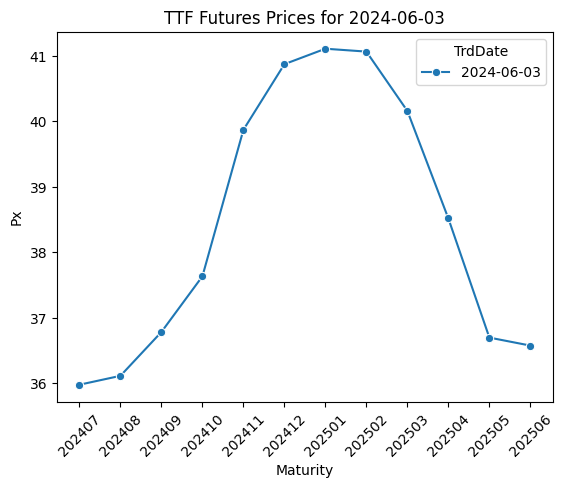

In [41]:
ax = sns.lineplot(
    data=random_observation.to_pandas()[:12],
    x="Maturity",
    y="Px",
    hue="TrdDate",
    marker="o",
)
ax.tick_params(axis="x", rotation=45)
ax.set_title("TTF Futures Prices for 2024-06-03")

### Log returns within each monthly delivery contract

For each fixed delivery month (`Maturity`), order settlement prices by trade date and calculate
$ r_{t,T} = \log(P_{t,T}) - \log(P_{t-1,T}) $.
Here $T$ stays fixed: returns follow the same contract over time.
Keep the latest timestamped correction for each contract/date pair and omit the first observation of each contract, which has no preceding price.
Returns span consecutive available observations, including weekends, holidays, or other gaps; they are not scaled by elapsed calendar days.
The histogram pools all contract returns, so contracts with longer histories contribute more observations, and contracts observed on the same date can be correlated.


In [7]:
# One settlement price per delivery month and trade date.
monthly_settlements = (
    monthly_futures.with_columns(pl.col("TrdDate").str.to_date())
    .sort(["Maturity", "TrdDate", "Tm", "CreationTm"])
    .unique(subset=["Maturity", "TrdDate"], keep="last")
    .sort(["Maturity", "TrdDate"])
)

# Mask invalid prices before differencing to avoid bridging across them.
monthly_log_returns = (
    monthly_settlements.with_columns(
        pl.when(pl.col("Px").is_finite() & (pl.col("Px") > 0))
        .then(pl.col("Px").log())
        .otherwise(None)
        .diff()
        .over("Maturity", order_by="TrdDate")
        .alias("log_return")
    )
    .filter(pl.col("log_return").is_finite())
    .select("TrdDate", "Maturity", "Px", "log_return")
)

monthly_log_returns.select(
    pl.len().alias("observations"),
    pl.col("Maturity").n_unique().alias("delivery_months"),
    pl.col("log_return").mean().alias("mean"),
    pl.col("log_return").std().alias("std_dev"),
    pl.col("log_return").min().alias("min"),
    pl.col("log_return").max().alias("max"),
)

shape: (1, 6)
┌──────────────┬─────────────────┬──────────┬──────────┬───────────┬──────────┐
│ observations ┆ delivery_months ┆ mean     ┆ std_dev  ┆ min       ┆ max      │
│ ---          ┆ ---             ┆ ---      ┆ ---      ┆ ---       ┆ ---      │
│ u32          ┆ u32             ┆ f64      ┆ f64      ┆ f64       ┆ f64      │
╞══════════════╪═════════════════╪══════════╪══════════╪═══════════╪══════════╡
│ 48071        ┆ 139             ┆ 0.000617 ┆ 0.034886 ┆ -0.422876 ┆ 0.420145 │
└──────────────┴─────────────────┴──────────┴──────────┴───────────┴──────────┘

### Comparison with a fitted normal distribution

Fit a normal distribution using the pooled returns' sample mean and sample standard deviation. The density plot compares the histogram with this normal benchmark. The second plot compares the worst 5% of returns using quantile curves at matched lower-tail percentiles. For example, at 1% it shows the return below which 1% of observations fall, alongside the fitted normal's 1% quantile. A lower empirical curve indicates more severe negative returns at that percentile; shading highlights these differences. The curve starts at the first empirical plotting position (0.5 / sample size), since the normal 0% quantile is unbounded.

Skewness measures asymmetry (normal: 0). [Excess kurtosis](https://docs.pola.rs/api/python/stable/reference/expressions/api/polars.Expr.kurtosis.html) measures standardized fourth-moment excess (normal: 0); positive values indicate greater extreme-return contributions. Tail frequencies compare both sides separately and together at 2, 3, 4, and 5 standard deviations from the mean. A tail ratio above 1 means more observed exceedances than under the fitted normal.

These are descriptive comparisons of pooled returns. Shared trade dates, changing volatility, differing maturities, and observation gaps can affect the pooled distribution, so these observations are not independent evidence for a formal normality-test p-value.


In [8]:
returns = monthly_log_returns["log_return"].to_numpy()
mu = float(returns.mean())
sigma = float(returns.std(ddof=1))
fitted_normal = NormalDist(mu=mu, sigma=sigma)
standardized_returns = (returns - mu) / sigma

summary_stats = pl.DataFrame(
    {
        "statistic": [
            "Mean",
            "Standard deviation",
            "Median",
            "Skewness",
            "Excess kurtosis",
            "Minimum",
            "1% quantile",
            "5% quantile",
            "95% quantile",
            "99% quantile",
            "Maximum",
        ],
        "empirical": [
            mu,
            sigma,
            float(np.median(returns)),
            monthly_log_returns["log_return"].skew(bias=False),
            monthly_log_returns["log_return"].kurtosis(
                fisher=True, bias=False
            ),
            float(returns.min()),
            *np.quantile(returns, [0.01, 0.05, 0.95, 0.99]).tolist(),
            float(returns.max()),
        ],
        "fitted_normal": [
            mu,
            sigma,
            mu,
            0.0,
            0.0,
            None,
            *[fitted_normal.inv_cdf(q) for q in [0.01, 0.05, 0.95, 0.99]],
            None,
        ],
    }
)
# Returns and quantiles are in decimal log-return units (0.01 = 1%).
# The theoretical normal has no finite minimum or maximum.
summary_stats.to_pandas()

,statistic,empirical,fitted_normal
0,Mean,0.000617,0.000617
1,Standard deviation,0.034886,0.034886
2,Median,0.000745,0.000617
3,Skewness,0.049017,0.000000
4,Excess kurtosis,15.836749,0.000000
5,Minimum,-0.422876,NaN
6,1% quantile,-0.104133,-0.080540
7,5% quantile,-0.049193,-0.056766
8,95% quantile,0.049389,0.057999
9,99% quantile,0.101302,0.081774


In [9]:
tail_rows = []
for threshold in [2, 3, 4, 5]:
    normal_one_tail = 0.5 * erfc(threshold / np.sqrt(2))
    left_count = int((standardized_returns < -threshold).sum())
    right_count = int((standardized_returns > threshold).sum())
    empirical_two_tail = (left_count + right_count) / returns.size
    tail_rows.append(
        {
            "threshold_sigma": threshold,
            "left_count": left_count,
            "right_count": right_count,
            "empirical_left_pct": 100 * left_count / returns.size,
            "empirical_right_pct": 100 * right_count / returns.size,
            "normal_each_tail_pct": 100 * normal_one_tail,
            "empirical_two_tail_pct": 100 * empirical_two_tail,
            "normal_two_tail_pct": 200 * normal_one_tail,
            "tail_ratio": empirical_two_tail / (2 * normal_one_tail),
        }
    )
tail_comparison = pl.DataFrame(tail_rows)
tail_comparison.to_pandas()

,threshold_sigma,left_count,right_count,empirical_left_pct,empirical_right_pct,normal_each_tail_pct,empirical_two_tail_pct,normal_two_tail_pct,tail_ratio
0,2,1220,1201,2.537913,2.498388,2.275013,5.036300,4.550026,1.106873
1,3,483,429,1.004764,0.892430,0.134990,1.897194,0.269980,7.027174
2,4,216,194,0.449335,0.403570,0.003167,0.852905,0.006334,134.649769
3,5,90,89,0.187223,0.185143,0.000029,0.372366,0.000057,6495.095649


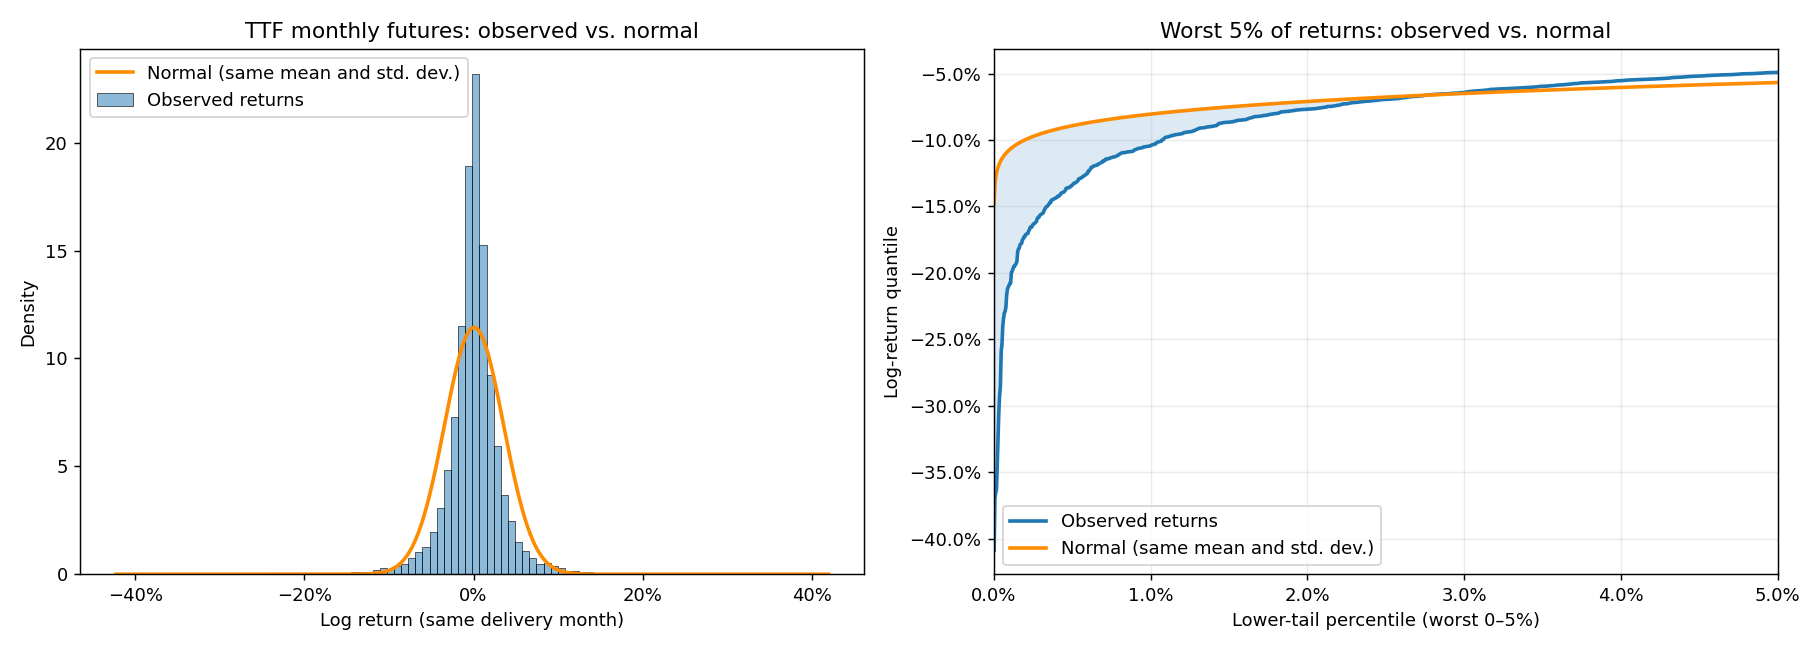

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    x=returns,
    bins=100,
    stat="density",
    alpha=0.5,
    label="Observed returns",
    ax=axes[0],
)
x = np.linspace(returns.min(), returns.max(), 2000)
normal_density = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (
    sigma * np.sqrt(2 * np.pi)
)
axes[0].plot(
    x,
    normal_density,
    color="darkorange",
    lw=2,
    label="Normal (same mean and std. dev.)",
)
axes[0].xaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[0].set(
    title="TTF monthly futures: observed vs. normal",
    xlabel="Log return (same delivery month)",
    ylabel="Density",
)
axes[0].legend()

# Compare return quantiles at the same lower-tail probabilities.
# Start at the first empirical plotting position to avoid normal p=0.
tail_probabilities = np.linspace(0.5 / returns.size, 0.05, 1000)
empirical_left_tail = np.quantile(returns, tail_probabilities)
normal_left_tail = np.array(
    [fitted_normal.inv_cdf(float(p)) for p in tail_probabilities]
)
axes[1].plot(
    tail_probabilities, empirical_left_tail, lw=2, label="Observed returns"
)
axes[1].plot(
    tail_probabilities,
    normal_left_tail,
    color="darkorange",
    lw=2,
    label="Normal (same mean and std. dev.)",
)
axes[1].fill_between(
    tail_probabilities,
    empirical_left_tail,
    normal_left_tail,
    where=empirical_left_tail < normal_left_tail,
    color="tab:blue",
    alpha=0.15,
)
axes[1].xaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].set(
    title="Worst 5% of returns: observed vs. normal",
    xlabel="Lower-tail percentile (worst 0–5%)",
    ylabel="Log-return quantile",
    xlim=(0, 0.05),
)
axes[1].grid(alpha=0.25)
axes[1].legend()
fig.tight_layout()
plt.show()